<a href="https://colab.research.google.com/github/febyataalya/PCVK-Ganjil-2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TUGAS PRAKTIKUM**

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

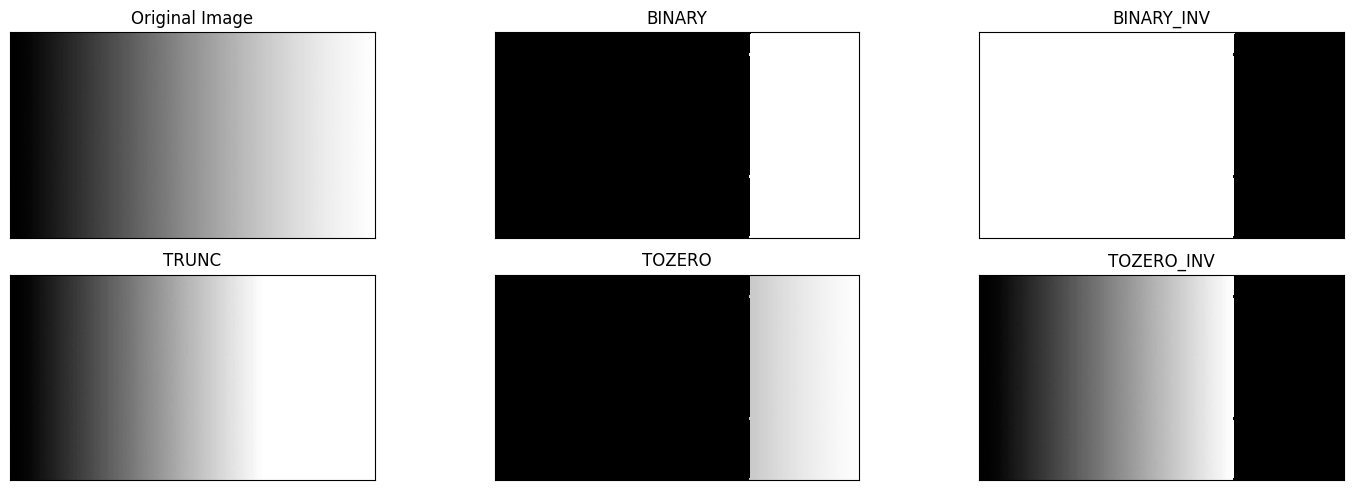

In [13]:
# 1. Baca citra dalam mode grayscale (pastikan path file sesuai di Google Drive Anda)
filename = '/content/drive/MyDrive/PCVK 2026/Images/gradient.jpg'
img = cv.imread(filename, 0)

# Tentukan nilai threshold dan nilai maksimal
thresh = 200
maxval = 255

# 2. Implementasi Global Thresholding secara Manual

# A. BINARY: > thresh menjadi maxval (255), lainnya menjadi 0
img_binary = np.where(img > thresh, maxval, 0).astype(np.uint8)

# B. BINARY_INV: > thresh menjadi 0, lainnya menjadi maxval (255)
img_binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)

# C. TRUNC: > thresh menjadi nilai thresh (200), lainnya nilai asli tetap
img_trunc = np.where(img > thresh, thresh, img).astype(np.uint8)

# D. TOZERO: > thresh nilai asli tetap, lainnya menjadi 0
img_tozero = np.where(img > thresh, img, 0).astype(np.uint8)

# E. TOZERO_INV: > thresh menjadi 0, lainnya nilai asli tetap
img_tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

# 3. Menampilkan Hasil Plotting dalam Grid 2x3
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, img_binary, img_binary_inv, img_trunc, img_tozero, img_tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

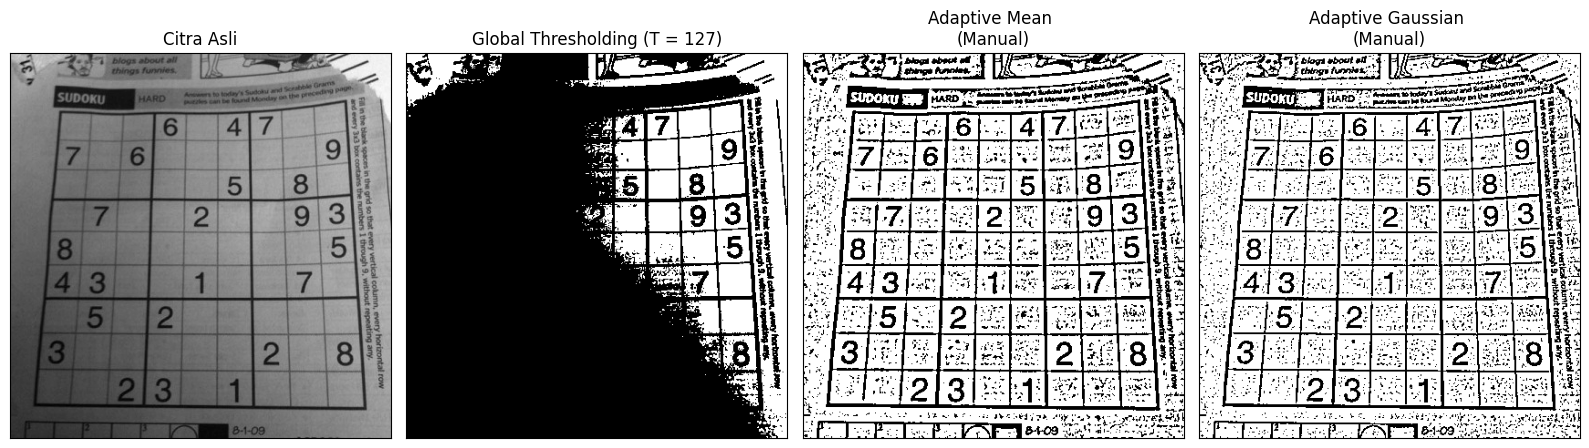

In [14]:
# 1. Baca citra Sudoku dalam mode grayscale (pastikan path sesuai di Google Drive)
filename = '/content/drive/MyDrive/PCVK 2026/Images/sudoku-original.jpg'
img = cv.imread(filename, 0)

if img is None:
    print(f"Error: Gagal membaca citra dari {filename}. Periksa kembali path file Anda!")
else:
    # 2. Global Thresholding secara Manual (T = 127)
    global_thresh = 127
    global_img = np.where(img > global_thresh, 255, 0).astype(np.uint8)

    # 3. Fungsi Manual untuk Adaptive Threshold (Mean & Gaussian) tanpa fungsi siap pakai
    def manual_adaptive_threshold(gray_img, block_size=11, C=2, method='mean', sigma=2):
        pad_len = block_size // 2
        # Padding citra menggunakan replikasi tepi (edge)
        padded = np.pad(gray_img, pad_len, mode='edge')
        H, W = gray_img.shape
        out = np.zeros((H, W), dtype=np.uint8)

        # Buat kernel Gaussian jika metodenya 'gaussian'
        if method == 'gaussian':
            ax = np.arange(-pad_len, pad_len + 1)
            xx, yy = np.meshgrid(ax, ax)
            kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
            kernel = kernel / np.sum(kernel) # Normalisasi bobot kernel agar jumlahnya 1

        # Iterasi melalui setiap piksel citra
        for i in range(H):
            for j in range(W):
                window = padded[i:i+block_size, j:j+block_size]

                if method == 'mean':
                    T = np.mean(window) - C
                elif method == 'gaussian':
                    T = np.sum(window * kernel) - C

                # Perbandingan piksel terhadap ambang batas lokal T(x,y)
                if gray_img[i, j] > T:
                    out[i, j] = 255
                else:
                    out[i, j] = 0

        return out

    # Eksekusi Adaptive Mean dan Adaptive Gaussian manual sesuai ketentuan modul
    adaptive_mean = manual_adaptive_threshold(img, block_size=11, C=2, method='mean')
    adaptive_gauss = manual_adaptive_threshold(img, block_size=11, C=2, method='gaussian', sigma=2)

    # 4. Plotting hasil perbandingan dalam 1 baris (4 kolom)
    titles = [
        'Citra Asli',
        'Global Thresholding (T = 127)',
        'Adaptive Mean \n(Manual)',
        'Adaptive Gaussian \n(Manual)'
    ]
    images = [img, global_img, adaptive_mean, adaptive_gauss]

    plt.figure(figsize=(16, 5))
    for i in range(len(images)):
        plt.subplot(1, 4, i + 1)
        plt.imshow(images[i], 'gray')
        plt.title(titles[i])
        plt.xticks([]), plt.yticks([])

    plt.tight_layout()
    plt.show()

93


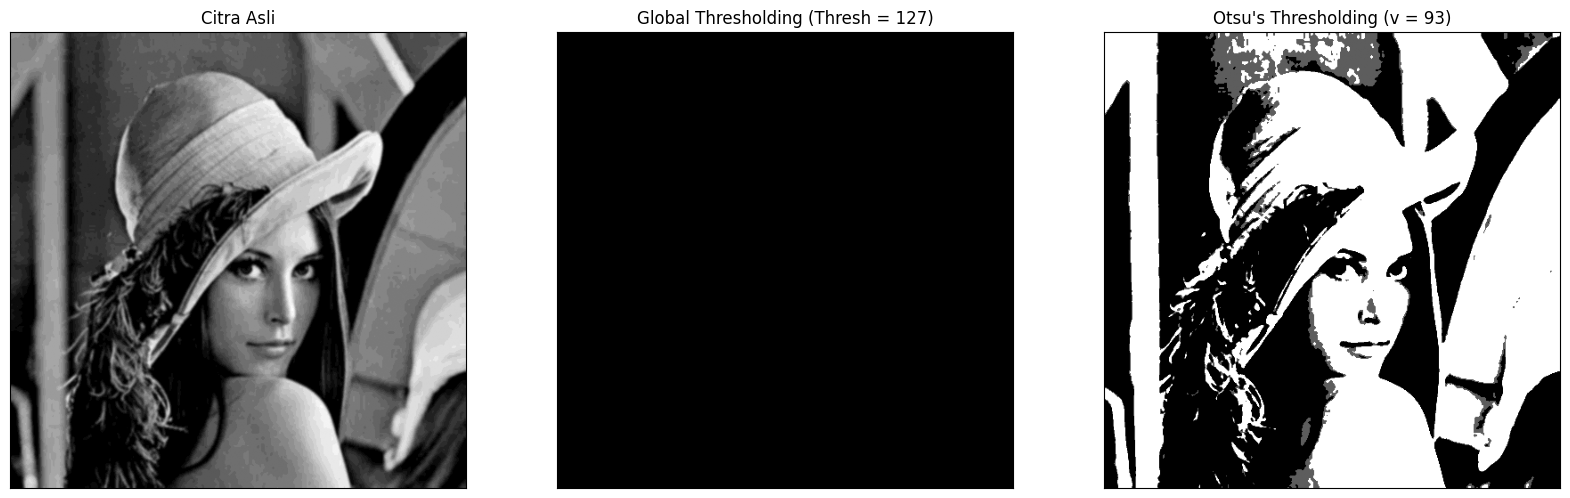

In [15]:
filename = ('/content/drive/MyDrive/PCVK 2026/Images/lena_gs_lc2.jpg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.show()

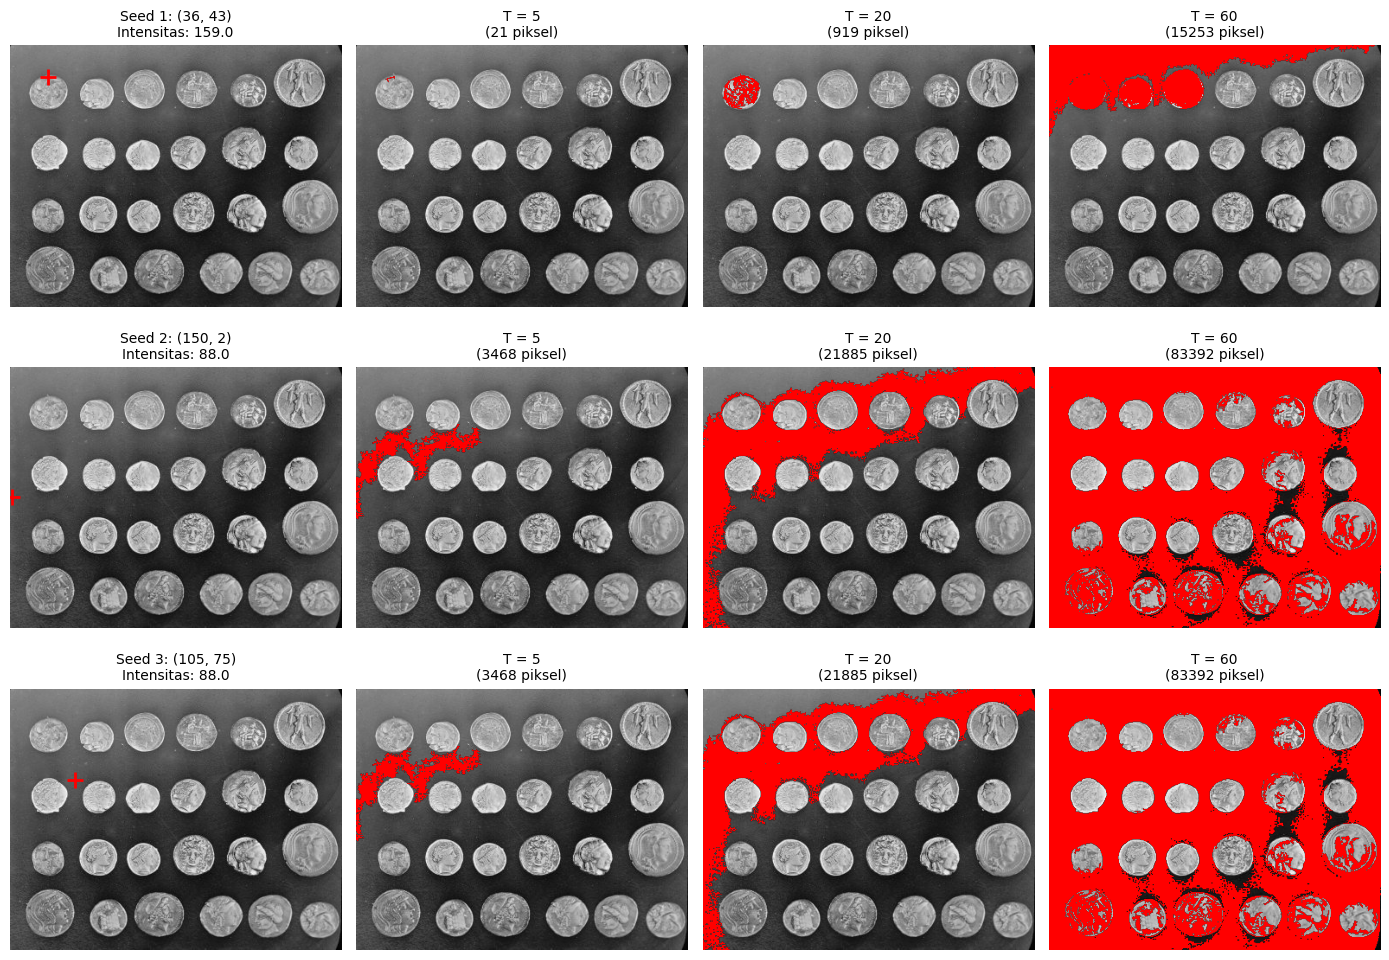

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load citra koin bawaan dari skimage (ukuran 303 x 384)
img = data.coins()
rows, cols = img.shape

seeds = [
    (36, 43),   # Titik 1: Di dalam koin
    (150, 2),   # Titik 2: Di area latar belakang
    (105, 75)   # Titik 3: Di garis tepi koin
]

# Variasi threshold yang mau diuji
thresholds = [5, 20, 60]

def region_growing(image, seed, threshold):
    # Fungsi dasar buat menjalankan algoritma region growing
    h, w = image.shape
    segmented = np.zeros((h, w), dtype=bool)
    visited = np.zeros((h, w), dtype=bool)

    seed_val = float(image[seed])
    queue = [seed]
    visited[seed] = True

    # Cek tetangga sekitar (atas, bawah, kiri, kanan)
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    while queue:
        r, c = queue.pop(0)
        segmented[r, c] = True

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not visited[nr, nc]:
                # Kalau selisih warna masih masuk batas threshold, ambil pikselnya
                if abs(float(image[nr, nc]) - seed_val) <= threshold:
                    segmented[nr, nc] = True
                    visited[nr, nc] = True
                    queue.append((nr, nc))
                else:
                    visited[nr, nc] = True

    return segmented

# Siapin kanvas plot grid 3x3 (plus kolom pertama buat nunjukkin posisi seed)
fig, axes = plt.subplots(len(seeds), len(thresholds) + 1, figsize=(14, 10))

for i, seed in enumerate(seeds):
    # Kolom 0: Gambar asli dengan tanda plus merah di posisi seed
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
    axes[i, 0].set_title(f"Seed {i+1}: {seed}\nIntensitas: {img[seed]:.1f}", fontsize=10)
    axes[i, 0].axis('off')

    for j, T in enumerate(thresholds):
        # Jalankan region growing untuk tiap nilai T
        seg = region_growing(img, seed, T)
        pixel_count = np.sum(seg)

        axes[i, j + 1].imshow(img, cmap='gray')
        red_overlay = np.zeros((*img.shape, 4))
        red_overlay[seg] = [1, 0, 0, 1.0]
        axes[i, j + 1].imshow(red_overlay)

        axes[i, j + 1].set_title(f"T = {T}\n({pixel_count} piksel)", fontsize=10)
        axes[i, j + 1].axis('off')

plt.tight_layout()
plt.show()

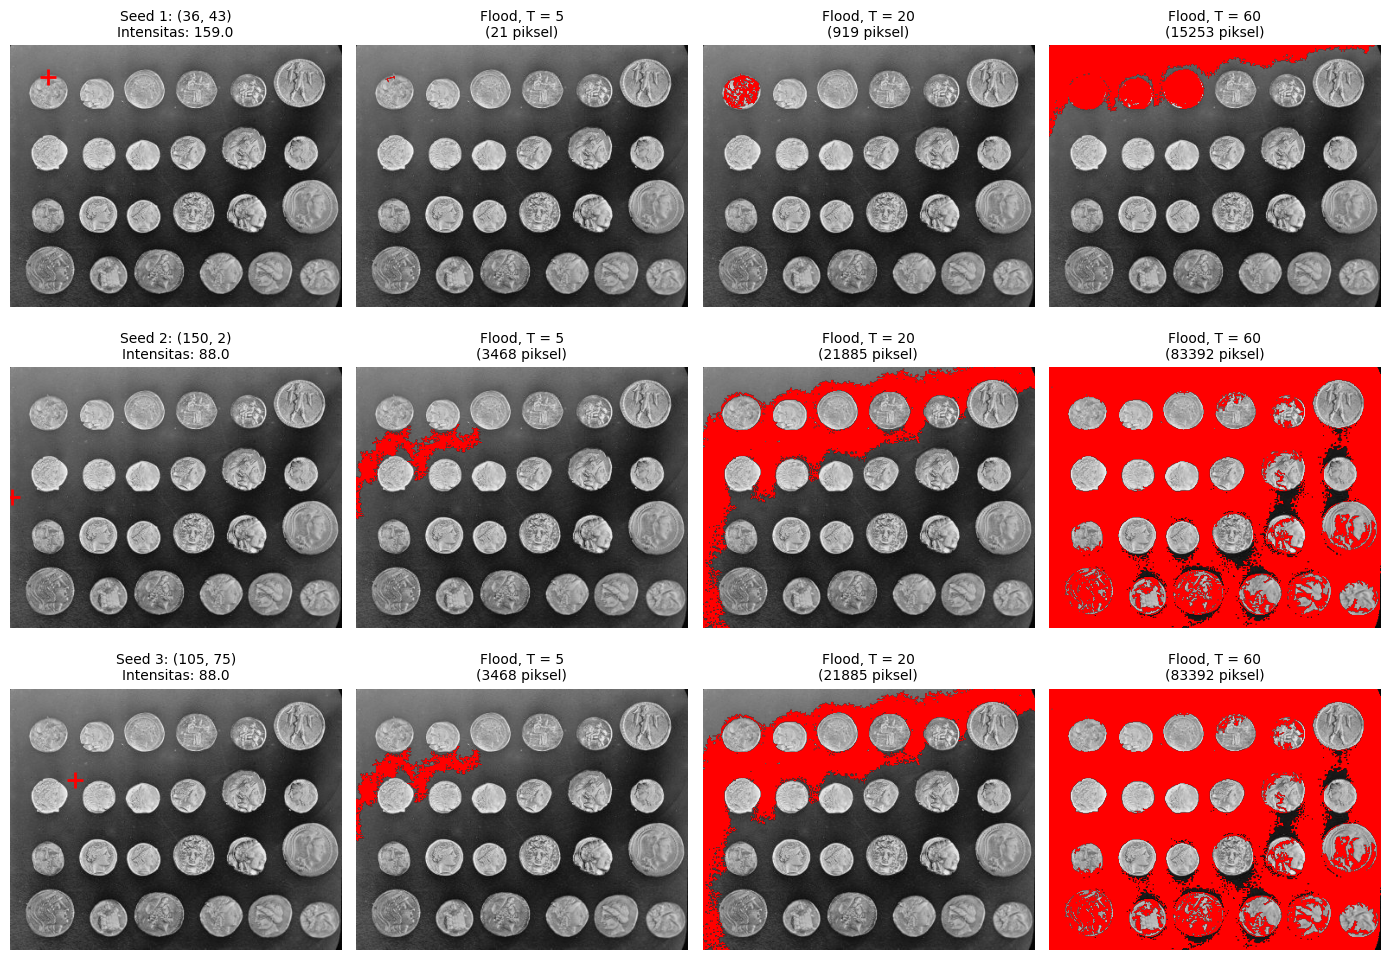

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

# Load citra koin bawaan dari skimage (ukuran 303 x 384)
img = data.coins()
rows, cols = img.shape

seeds = [
    (36, 43),   # Titik 1: Di dalam koin
    (150, 2),   # Titik 2: Di latar belakang
    (105, 75)   # Titik 3: Di tepi koin
]

# Variasi nilai tolerance (T) yang diminta
tolerances = [5, 20, 60]

# Siapin kanvas plot grid 3x3 (plus kolom pertama buat nunjukkin posisi seed)
fig, axes = plt.subplots(len(seeds), len(tolerances) + 1, figsize=(14, 10))

for i, seed in enumerate(seeds):
    # Kolom 0: Gambar asli dengan tanda plus merah di posisi seed
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
    axes[i, 0].set_title(f"Seed {i+1}: {seed}\nIntensitas: {img[seed]:.1f}", fontsize=10)
    axes[i, 0].axis('off')

    for j, tol in enumerate(tolerances):
        # Jalankan fungsi bawaan flood() dari skimage
        seg = flood(img, seed_point=seed, tolerance=tol, connectivity=1)
        pixel_count = np.sum(seg)

        # Tampilkan hasil di grid dengan overlay warna merah pekat (alpha 1.0)
        axes[i, j + 1].imshow(img, cmap='gray')
        red_overlay = np.zeros((*img.shape, 4))
        red_overlay[seg] = [1, 0, 0, 1.0]  # Warna merah tebal/pekat penuh
        axes[i, j + 1].imshow(red_overlay)

        axes[i, j + 1].set_title(f"Flood, T = {tol}\n({pixel_count} piksel)", fontsize=10)
        axes[i, j + 1].axis('off')

plt.tight_layout()
plt.show()

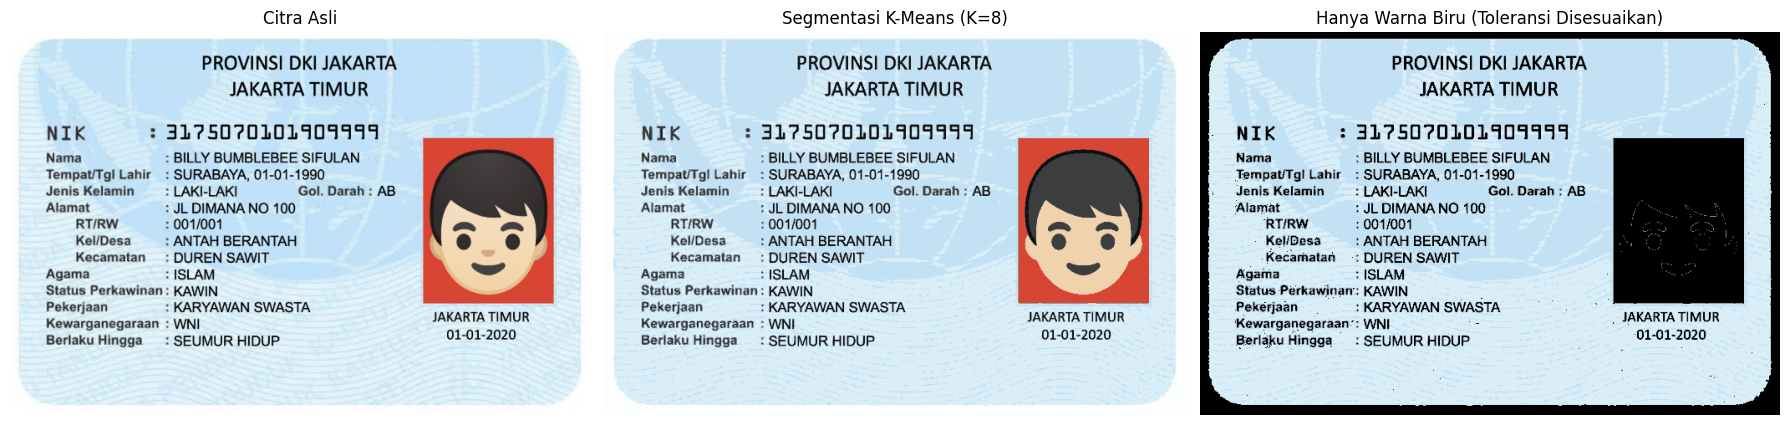

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage import color

# 1. Memuat citra dari Google Drive
filename = '/content/drive/MyDrive/PCVK 2026/Images/ktp_fulan.jpg'
citra_asli = cv2.imread(filename)

if citra_asli is None:
    filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
    citra_asli = cv2.imread(filename)

citra_asli_rgb = cv2.cvtColor(citra_asli, cv2.COLOR_BGR2RGB)

# 2. Segmentasi K-Means (K=8)
rows, cols, ch = citra_asli_rgb.shape
pixels = citra_asli_rgb.reshape(-1, ch)

kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans.fit(pixels)
segmented_colors = kmeans.cluster_centers_[kmeans.labels_]
citra_kmeans = segmented_colors.reshape(rows, cols, ch).astype(np.uint8)

# 3. Konversi hasil K-Means ke ruang warna HSV (skala 0-1)
citra_hsv = color.rgb2hsv(citra_kmeans)

# Gunakan skala 0-1 langsung agar lebih aman dari perbedaan pustaka (skimage vs OpenCV)
# Rentang Hue biru dalam skimage biasanya berada di sekitar 0.5 hingga 0.65 (ekuivalen 180°-230°)
# Atau kita gunakan rentang yang sangat longgar untuk memastikan tidak hitam:
H = citra_hsv[:, :, 0]
S = citra_hsv[:, :, 1]
V = citra_hsv[:, :, 2]

# Coba rentang alternatif yang lebih luas untuk mencakup latar KTP Anda:
# Hue 0.5 sampai 0.7 setara dengan warna Cyan/Biru
mask = (H >= 0.45) & (H <= 0.75) & (S >= 0.10) & (V >= 0.20)

# Jika mask masih kosong (semua False), gunakan cara otomatis: ambil warna latar dominan
if np.sum(mask) == 0:
    print("Mask awal kosong, memperluas rentang warna...")
    mask = (S >= 0.05) & (V >= 0.3) # Menyaring area yang memiliki warna (tidak terlalu putih/hitam)

# 4. Membuat citra akhir "Hanya Warna Biru"
hanya_biru = np.zeros_like(citra_kmeans)
hanya_biru[mask] = citra_kmeans[mask]

# 5. Menampilkan hasil
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(citra_asli_rgb)
axes[0].set_title('Citra Asli')
axes[0].axis('off')

axes[1].imshow(citra_kmeans)
axes[1].set_title('Segmentasi K-Means (K=8)')
axes[1].axis('off')

axes[2].imshow(hanya_biru)
axes[2].set_title('Hanya Warna Biru (Toleransi Disesuaikan)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

**TUGAS PRAKTIKUM KELOMPOK**

In [19]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


========== HASIL OCR: BERWARNA ASLI ==========
KTM VIRTUAL
FEBYATA ALYA AWANDHINI
264107027013
joraO
S3


========== HASIL OCR: OTSU THRESHOLDING ==========
KTM VIRTUAL
FEBYATA ALYA AWANDHINI
264107027013
&
GE


========== HASIL OCR: ADAPTIVE THRESHOLDING ==========
...KTM VIRTUAL.....
rei
aa
TI FEBYATATALYA"AWANDHINI
(| Asa BN 7
CAS ing DIV INFORMATIKA
pr
jo)
aw




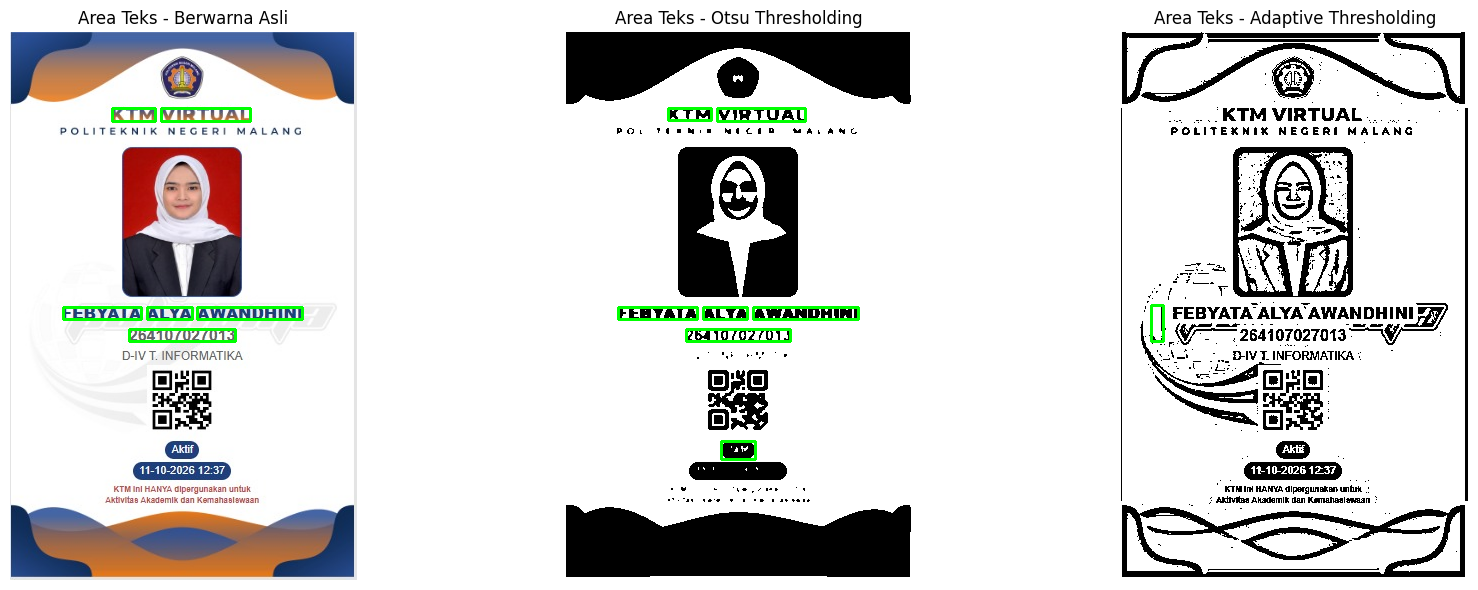

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract

# 1. Memuat citra KTP dari Google Drive
filename = '/content/drive/MyDrive/PCVK 2026/KTM ALYA.jpg'
img_color = cv2.imread(filename)
if img_color is None:
    filename = '/content/drive/MyDrive/PCVK 2026/KTM ALYA.jpg'
    img_color = cv2.imread(filename)

# 2. Menyiapkan 3 jenis citra (Berwarna/Grayscale, Otsu, Adaptive)
img_berwarna_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Otsu Thresholding
blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, img_otsu_bin = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
img_otsu_rgb = cv2.cvtColor(img_otsu_bin, cv2.COLOR_GRAY2RGB)

# Adaptive Thresholding (Mean)
img_adaptive_bin = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 2
)
img_adaptive_rgb = cv2.cvtColor(img_adaptive_bin, cv2.COLOR_GRAY2RGB)

# Kelompokkan data untuk perulangan
daftar_citra = [
    ("Berwarna Asli", img_berwarna_rgb, gray),
    ("Otsu Thresholding", img_otsu_rgb, img_otsu_bin),
    ("Adaptive Thresholding", img_adaptive_rgb, img_adaptive_bin)
]

# Konfigurasi Tesseract (Bahasa Indonesia 'ind', PSM 6 untuk blok teks)
custom_config = r'--oem 3 --psm 6 -l ind'

# 3. Proses Visualisasi Gambar dengan Kotak Hijau & Cetak Teks Hasil OCR
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, (nama_metode, img_tampil, img_proses) in enumerate(daftar_citra):
    # Salin citra untuk digambari kotak hijau
    img_boxed = img_tampil.copy()

    # Ambil data koordinat kotak teks dari Tesseract (confidence > 60)
    data = pytesseract.image_to_data(img_proses, config=custom_config, output_type=pytesseract.Output.DICT)
    n_boxes = len(data['text'])
    for j in range(n_boxes):
        conf = int(data['conf'][j])
        if conf > 60:
            x, y, w, h = data['left'][j], data['top'][j], data['width'][j], data['height'][j]
            cv2.rectangle(img_boxed, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # Tampilkan gambar hasil bounding box di subplot
    axes[i].imshow(img_boxed)
    axes[i].set_title(f"Area Teks - {nama_metode}")
    axes[i].axis('off')

    # Cetak teks hasil bacaan OCR ke konsol/output Colab
    print(f"========== HASIL OCR: {nama_metode.upper()} ==========")
    teks_bacaan = pytesseract.image_to_string(img_proses, config=custom_config)
    print(teks_bacaan)
    print("=" * 50 + "\n")

plt.tight_layout()
plt.show()

========== HASIL OCR: BERWARNA ASLI ==========
KTM VIRTUAL
5
ulu
ILSA ALZIZA KHAN GANDEGUAY
264107027007
EM)


========== HASIL OCR: OTSU THRESHOLDING ==========
KTM VIRTUAL
ILSA ALZIZA KHAN GANDEGUAY
264107027007
aya
ana
.
cc...


========== HASIL OCR: ADAPTIVE THRESHOLDING ==========
HT KTM VIRTUAL:
POLITEKNIKINEGERI MALANG
:
&
Ie
»
HILSA'ALZIZA" KHAN GANDEGUAY 2
"GA 26A107027007 AD
Mn DARMA
Setan
2.
.
'enimtonnanngnamara




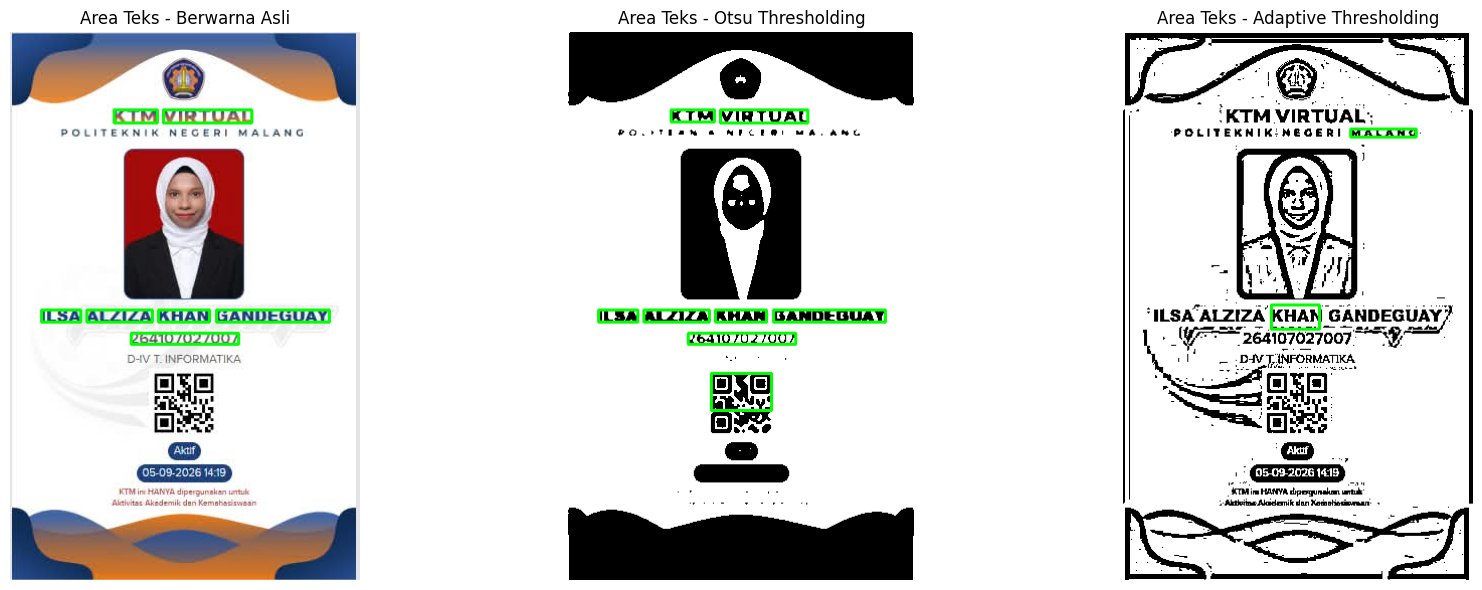

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract

# 1. Memuat citra KTP dari Google Drive
filename = '/content/drive/MyDrive/PCVK 2026/Ilsa KTM.jpeg'
img_color = cv2.imread(filename)
if img_color is None:
    filename = '/content/drive/MyDrive/PCVK 2026/Ilsa KTM.jpeg'
    img_color = cv2.imread(filename)

# 2. Menyiapkan 3 jenis citra (Berwarna/Grayscale, Otsu, Adaptive)
img_berwarna_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Otsu Thresholding
blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, img_otsu_bin = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
img_otsu_rgb = cv2.cvtColor(img_otsu_bin, cv2.COLOR_GRAY2RGB)

# Adaptive Thresholding (Mean)
img_adaptive_bin = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 2
)
img_adaptive_rgb = cv2.cvtColor(img_adaptive_bin, cv2.COLOR_GRAY2RGB)

# Kelompokkan data untuk perulangan
daftar_citra = [
    ("Berwarna Asli", img_berwarna_rgb, gray),
    ("Otsu Thresholding", img_otsu_rgb, img_otsu_bin),
    ("Adaptive Thresholding", img_adaptive_rgb, img_adaptive_bin)
]

# Konfigurasi Tesseract (Bahasa Indonesia 'ind', PSM 6 untuk blok teks)
custom_config = r'--oem 3 --psm 6 -l ind'

# 3. Proses Visualisasi Gambar dengan Kotak Hijau & Cetak Teks Hasil OCR
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, (nama_metode, img_tampil, img_proses) in enumerate(daftar_citra):
    # Salin citra untuk digambari kotak hijau
    img_boxed = img_tampil.copy()

    # Ambil data koordinat kotak teks dari Tesseract (confidence > 60)
    data = pytesseract.image_to_data(img_proses, config=custom_config, output_type=pytesseract.Output.DICT)
    n_boxes = len(data['text'])
    for j in range(n_boxes):
        conf = int(data['conf'][j])
        if conf > 60:
            x, y, w, h = data['left'][j], data['top'][j], data['width'][j], data['height'][j]
            cv2.rectangle(img_boxed, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # Tampilkan gambar hasil bounding box di subplot
    axes[i].imshow(img_boxed)
    axes[i].set_title(f"Area Teks - {nama_metode}")
    axes[i].axis('off')

    # Cetak teks hasil bacaan OCR ke konsol/output Colab
    print(f"========== HASIL OCR: {nama_metode.upper()} ==========")
    teks_bacaan = pytesseract.image_to_string(img_proses, config=custom_config)
    print(teks_bacaan)
    print("=" * 50 + "\n")

plt.tight_layout()
plt.show()